# Find where amg spends its time

You'll plot how long amg's `main` takes as the number of processes grows, and find which calls inside `main` take that time.
It takes about 15 minutes of your time.

Select a cell and press Shift+Enter to run it.
This notebook runs on corona, after [Count the runs](01-count-the-runs.ipynb) made the link to the sample.

## Settings and check

In [1]:
%env DFTRACER_UTILS_LOG_LEVEL=warn

env: DFTRACER_UTILS_LOG_LEVEL=warn


In [2]:
import os

SAMPLE = "../data/genesis-sample.pfw.gz"
print(SAMPLE, os.path.getsize(SAMPLE), "bytes")

../data/genesis-sample.pfw.gz 161541455 bytes


The size must be 161541455 bytes.
If the file is missing, run the settings cells of [Count the runs](01-count-the-runs.ipynb) first.

## 1. Read the runs and the call paths

A `func` record holds the duration of one call path of one run, over all its processes.
`filter` with a `col` condition picks records inside the engine, so only the `func` records reach Python.

In [3]:
from dftracer.utils import Indexer, TraceViewer, col

with Indexer(files=[SAMPLE]) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(SAMPLE)
func = tv.filter(col("gtype") == "func").collect()
func.shape

(23075, 19)

23,075 call paths, out of almost 5 million records in the sample.

## 2. Read one call path

In [4]:
main = func[(func["name"] == "main") & (func["depth"] == 0)]
main[["run", "path", "count", "dur.p50", "dur.max"]].sort_values("run").head(3)

                run  path  count       dur.p50       dur.max
0  00408f6a9c4994b2  main      4  1.567006e+08  1.567006e+08
1  010d8a3fb3f5751d  main      2  9.097600e+04  9.869900e+04
2  021f52cc43d47c4e  main      4  1.056776e+08  1.057050e+08

`count` is the number of calls, one for each process here.
`dur.p50` is the median call duration and `dur.max` the longest one, both in microseconds.

## 3. Add the run settings

A `func` record names its run by id only.
`merge` adds the columns of `runs` to each record with the same `run`, as in pandas.

In [5]:
main = main.merge(runs, on="run")
amg = main[(main["app"] == "amg") & (main["system"] == "matrix") & (main["unique_input"] == "p1_n64x64x32")]
amg = amg.assign(p50_s=amg["dur.p50"] / 1e6)
amg[["nodes", "ppn", "papi_set", "count", "p50_s"]].sort_values(["nodes", "ppn", "papi_set"])

    nodes  ppn                papi_set  count     p50_s
0       1    2          papi_set2_flop      2  0.838144
1       1    4  papi_set1_branch_cycle      4  0.977782
2       1    8          papi_set2_flop      8  1.264006
3       1   16  papi_set1_branch_cycle     16  1.813067
4       2    1  papi_set1_branch_cycle      2  0.900321
5       2    1          papi_set2_flop      2  0.882493
6       2    2          papi_set2_flop      4  0.937065
7       2    8          papi_set2_flop     16  1.316543
8       4    1  papi_set1_branch_cycle      4  0.975309
9       4    2          papi_set2_flop      8  1.056543
10      4    8  papi_set1_branch_cycle     32  1.397956
11      8    1          papi_set2_flop      8  1.077887
12      8    2          papi_set2_flop     16  1.144542
13      8    4  papi_set1_branch_cycle     32  1.426197
14      8    4          papi_set2_flop     32  1.290473

Each row is one run.
Two settings show up twice, such as 2 nodes with 1 process per node, because they ran once for each counter set.

## 4. Take the median of each setting

The two runs of one setting are the same program, so group them and take the median.
Use the method `.median()`, which is exact.
`agg({"p50_s": "median"})` is refused, because the engine's `agg` median is an estimate from a sketch.

In [6]:
scaling = amg[["nodes", "ppn", "p50_s"]].groupby(["nodes", "ppn"]).median().to_pandas()
scaling

,nodes,ppn,p50_s
0,1,2,0.838144
1,1,4,0.977782
2,1,8,1.264006
3,1,16,1.813067
4,2,1,0.891407
5,2,2,0.937065
6,2,8,1.316543
7,4,1,0.975309
8,4,2,1.056543
9,4,8,1.397956


One row for each setting now, with the median of the runs' medians.

## 5. Plot the time against the processes

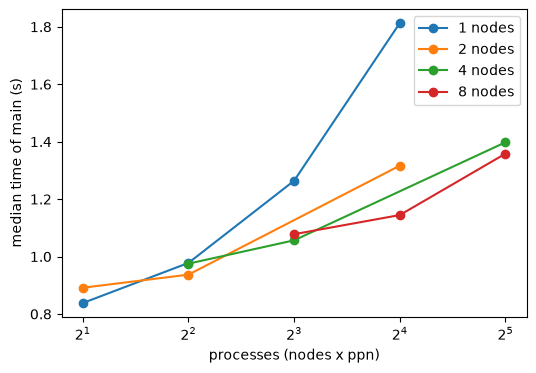

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for nodes, rows in scaling.groupby("nodes"):
    ax.plot(rows["ppn"] * nodes, rows["p50_s"], marker="o", label=f"{nodes} nodes")
ax.set_xscale("log", base=2)
ax.set_xlabel("processes (nodes x ppn)")
ax.set_ylabel("median time of main (s)")
ax.legend()
plt.show()

Each line is one number of nodes.
On one node the time climbs from 0.84 s at 2 processes to 1.81 s at 16, while more nodes with fewer processes each stay lower.
Each process gets the same problem size here, so the extra time comes from packing more processes on one node.

## 6. Find the slow calls inside main

Take the run with 8 nodes and 4 processes per node that has the cycle counters.
The calls directly inside `main` have `depth` 1, and `nlargest` keeps the rows with the largest total time.

In [8]:
RUN = "5400adb996f10a22"
inside = func[(func["run"] == RUN) & (func["depth"] == 1)].nlargest(5, "dur.sum")
inside = inside.assign(total_s=inside["dur.sum"] / 1e6, p50_ms=inside["dur.p50"] / 1e3)
inside[["path", "count", "total_s", "p50_ms"]]

                          path  count    total_s      p50_ms
0          main;hypre_PCGSolve     32  25.719681  803.734000
1          main;hypre_PCGSetup     32  12.411026  387.855000
2    main;BuildIJLaplacian27pt     32   6.323746  217.609988
3       main;hypre_PrintTiming     32   0.213410    6.838641
4  main;hypre_BoomerAMGDestroy     32   0.015332    0.487971

`hypre_PCGSolve` takes the most time, and `hypre_PCGSetup` comes second.
`total_s` adds up all processes, so it's larger than the wall time of the run.

## 7. Compare a smaller input

The input `p1_n32x32x16` is 8 times smaller.

In [9]:
small = main[(main["app"] == "amg") & (main["system"] == "matrix") & (main["unique_input"] == "p1_n32x32x16")]
small = small.assign(p50_s=small["dur.p50"] / 1e6)
small[["nodes", "ppn", "p50_s"]].groupby(["nodes", "ppn"]).median()

   nodes  ppn     p50_s
0      1    1  0.071310
1      1    8  0.151820
2      1   16  0.282227
3      2    1  0.090976
4      2    2  0.101766
5      2    8  0.167787
6      4    1  0.107246
7      4    2  0.134651
8      4    4  0.265791
9      8    1  0.134651

`main` takes about 0.28 s with 16 processes on one node, against 1.81 s for the larger input.
The time drops by more than 6 times while the work drops by 8 times, so part of the time doesn't shrink with the input.

## What you built

You loaded the call paths of a trace, joined each one to its run settings, grouped the runs of one setting and plotted them.
The next notebook is [Count instructions per cycle](03-count-instructions-per-cycle.ipynb).

- What the `func` fields mean: [Build per-function distributions from genesis traces](https://dftracer.readthedocs.io/projects/utils/en/latest/guides/tools/genesis-gen-dist.html)
- The pandas spellings the engine takes: [Python API Reference](https://dftracer.readthedocs.io/projects/utils/en/latest/api/index.html)